# 07 — Oil-specific geopolitical risk and Brent volatility transitions

**Research status:** retrospective extension. The AI-GPR series was developed in 2026 and reconstructed historically; lagging its published historical values cannot establish that those values were available at each forecast date. The 2020–2026 period has already been examined in Stages 05–06, so new-model results there are exploratory historical evidence.

Sources: [official AI-GPR download and definitions](https://www.matteoiacoviello.com/ai_gpr.html) and [Iacoviello and Tong (2026), methodology paper](https://www.matteoiacoviello.com/research_files/AI_GPR_PAPER.pdf). The paper describes AI article intensity scores normalized by total articles, oil-supply disruption classification, and the source-matched keyword benchmark.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd() if (Path.cwd() / "data" / "processed").is_dir() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "code"))
from stage07_oil_specific_gpr import run, TABLES, FIGURES
from IPython.display import display, Markdown, Image
results = run()

## Stage 06 paired-bootstrap audit

The saved WTI loss is M1 QLIKE minus M4 QLIKE, so positive values favor M4. Reproducing the original circular block bootstrap gives an absolute-tail two-sided p-value near 0.0475. The basic 95% interval uses equal tails of a skewed centered bootstrap distribution and includes zero. Its matching equal-tail two-sided p-value is near 0.0820. The original file is retained, and the correction is separately exported. This does not establish a robust WTI M4 improvement.

In [2]:
display(results["correction"].round(5))
display(Markdown("### Source definitions"))
display(results["definitions"])
display(Markdown("### Coverage and quality"))
display(results["coverage"].round(3))

,comparison,n,mean_difference,sign,original_absolute_tail_p,corrected_equal_tail_p_consistent_with_basic_ci,basic_ci95_low,basic_ci95_high,lower_tail_probability,upper_tail_probability,block_length,replications,seed
0,WTI test M1 minus M4 QLIKE,1703,0.03696,positive favors M4,0.04748,0.08196,-0.00571,0.06777,0.95952,0.04098,10,2000,7205


### Source definitions

,column,meaning,construction,file
0,GPRD,Original broad daily GPR (Stages 01–06),10-newspaper recent keyword index; revised dai...,data_gpr_daily_recent.xls
1,GPR_AI,General AI-GPR,Intensity-weighted LLM scores divided by all a...,ai_gpr_data_daily.csv
2,GPR_OIL,Oil GPR,LLM-classified geopolitical oil/energy supply ...,ai_gpr_data_daily.csv
3,GPR_OIL_THREATS,Oil Threats GPR,Oil disruption articles classified as threats ...,ai_gpr_data_daily.csv
4,GPR_OIL_ACTS,Oil Acts GPR,Oil disruption articles classified as acts or ...,ai_gpr_data_daily.csv
5,GPR_AER,Source-matched keyword GPR,Proximity keyword method applied to same 3 new...,ai_gpr_data_daily.csv


### Coverage and quality

,index,split,n,missing,zero,mean,sd,p10,median,p90,maximum,first_date,last_date
0,GPR_AI,test,1712,0,0,135.089,64.729,60.036,130.415,214.800,498.32,2020-01-02,2026-10-26
1,GPR_AI,train,3699,0,0,96.565,41.198,53.630,90.550,143.344,499.07,2000-01-04,2015-12-31
2,GPR_AI,validation,999,0,0,104.034,31.408,68.198,100.110,145.486,255.32,2016-01-04,2019-12-31
3,GPR_OIL,test,1712,0,563,223.574,354.181,0.000,105.460,587.474,3539.73,2020-01-02,2026-10-26
4,GPR_OIL,train,3699,0,874,101.739,110.147,0.000,71.900,241.670,1209.49,2000-01-04,2015-12-31
5,GPR_OIL,validation,999,0,359,93.521,111.467,0.000,73.730,238.360,1415.97,2016-01-04,2019-12-31
6,GPR_AER,test,1712,0,9,125.626,74.691,42.878,112.205,226.166,514.27,2020-01-02,2026-10-26
7,GPR_AER,train,3699,0,5,100.695,57.934,41.544,90.690,167.892,610.18,2000-01-04,2015-12-31
8,GPR_AER,validation,999,0,5,92.736,46.174,40.736,85.710,153.490,298.08,2016-01-04,2019-12-31
9,GPR_OIL_THREATS,test,1712,0,784,218.460,363.018,0.000,108.115,600.940,3536.31,2020-01-02,2026-10-26


## Models and timing

M4 uses lagged VIX; M5 uses the original broad daily GPR and VIX; E1 uses general AI-GPR and VIX; E2 uses Oil GPR and VIX; E3 uses source-matched keyword `GPR_AER` and VIX. All have the same Gaussian two-state switching-mean and switching-variance observation equation, an explicit transition intercept, and the same Brent observations. New newspaper indices use the previous **calendar day**; VIX uses the preceding observed market quote. Each predictor is standardized using the fitting period only. Validation fits end in 2015; exploratory test fits end in 2019. The test return is assimilated into the filtered state only after its forecast is recorded. Smoothed states are used only for retrospective descriptions.

In [3]:
display(Markdown("### Matched-sample training fit"))
display(results["diagnostics"].query("period == 'validation'")[["model","n","llf","aic","bic","successful_starts","failed_starts","ll_spread","missing_se","minimum_transition"]].round(5))
display(Markdown("### Regime descriptions"))
display(results["regimes"].query("period == 'validation'").round(4))
display(Markdown("### Complete parameter estimates and standard errors"))
display(results["parameters"].query("period == 'validation'").round(5))

### Matched-sample training fit

,model,n,llf,aic,bic,successful_starts,failed_starts,ll_spread,missing_se,minimum_transition
0,M4,3699,-8029.99711,16075.99421,16125.72076,3,0,0.00000,0,0.00004
1,M5,3699,-8025.59063,16071.18125,16133.33943,3,0,0.00001,0,0.00004
2,E1,3699,-8029.25710,16078.51421,16140.67238,3,0,0.00000,0,0.00004
3,E2,3699,-8026.97059,16073.94118,16136.09936,3,0,0.00001,0,0.00002
4,E3,3699,-8026.73742,16073.47485,16135.63302,3,0,0.00001,0,0.00002


### Regime descriptions

,period,model,state,original_state,mean_pct,sd_pct,filtered_occupancy,smoothed_occupancy_retrospective,average_stay_probability
0,validation,M4,Low,0,0.1053,1.6095,0.7363,0.7301,0.9657
1,validation,M4,High,1,-0.2498,3.6459,0.2637,0.2699,0.8614
2,validation,M5,Low,0,0.1094,1.6325,0.7479,0.7406,0.9644
3,validation,M5,High,1,-0.2758,3.6738,0.2521,0.2594,0.8749
4,validation,E1,Low,0,0.1096,1.6301,0.7428,0.7361,0.9698
5,validation,E1,High,1,-0.2696,3.6518,0.2572,0.2639,0.8803
6,validation,E2,Low,0,0.0963,1.6186,0.7556,0.7520,0.9561
7,validation,E2,High,1,-0.2538,3.7625,0.2444,0.2480,0.8038
8,validation,E3,Low,0,0.1096,1.6253,0.7389,0.7328,0.9654
9,validation,E3,High,1,-0.2651,3.6397,0.2611,0.2672,0.8792


### Complete parameter estimates and standard errors

,period,model,parameter,estimate,std_error
0,validation,M4,p[0->0].tvtp0,3.34509,0.26800
1,validation,M4,p[1->0].tvtp0,-2.15860,0.32098
2,validation,M4,p[0->0].tvtp1,0.11692,0.27058
3,validation,M4,p[1->0].tvtp1,-1.17558,0.39669
4,validation,M4,const[0],0.10530,0.03649
5,validation,M4,const[1],-0.24977,0.12790
6,validation,M4,sigma2[0],2.59059,0.16219
7,validation,M4,sigma2[1],13.29239,1.08845
8,validation,M5,p[0->0].tvtp0,3.60444,0.30658
9,validation,M5,p[1->0].tvtp0,-2.27799,0.29128


### Geopolitical-risk percentile scenarios

,period,model,predictor,transition,raw_p10,raw_p90,probability_p10,probability_p90,difference_pp,delta_se_pp,ci95_low_pp,ci95_high_pp
0,validation,M4,vix,low_to_high,12.3900,31.1780,0.0378,0.0298,-0.7946,1.7998,-4.3223,2.7331
1,validation,M4,vix,high_to_high,12.3900,31.1780,0.7473,0.9719,22.4575,9.7986,3.2522,41.6628
2,validation,M5,original_gpr,low_to_high,52.7144,164.3038,0.0163,0.0519,3.5660,1.2755,1.0660,6.0660
3,validation,M5,original_gpr,high_to_high,52.7144,164.3038,0.9017,0.8506,-5.1049,4.9504,-14.8078,4.5979
4,validation,E1,ai_gpr,low_to_high,53.6300,143.3440,0.0178,0.0453,2.7493,1.2147,0.3685,5.1300
5,validation,E1,ai_gpr,high_to_high,53.6300,143.3440,0.9039,0.8600,-4.3880,4.0296,-12.2859,3.5100
6,validation,E2,oil_gpr,low_to_high,0.0000,241.6700,0.0730,0.0145,-5.8547,3.0312,-11.7958,0.0865
7,validation,E2,oil_gpr,high_to_high,0.0000,241.6700,0.8038,0.8076,0.3808,7.5436,-14.4048,15.1663
8,validation,E3,matched_keyword_gpr,low_to_high,41.5440,167.8920,0.0122,0.0588,4.6662,1.4331,1.8573,7.4752
9,validation,E3,matched_keyword_gpr,high_to_high,41.5440,167.8920,0.9290,0.8252,-10.3789,5.1401,-20.4535,-0.3043


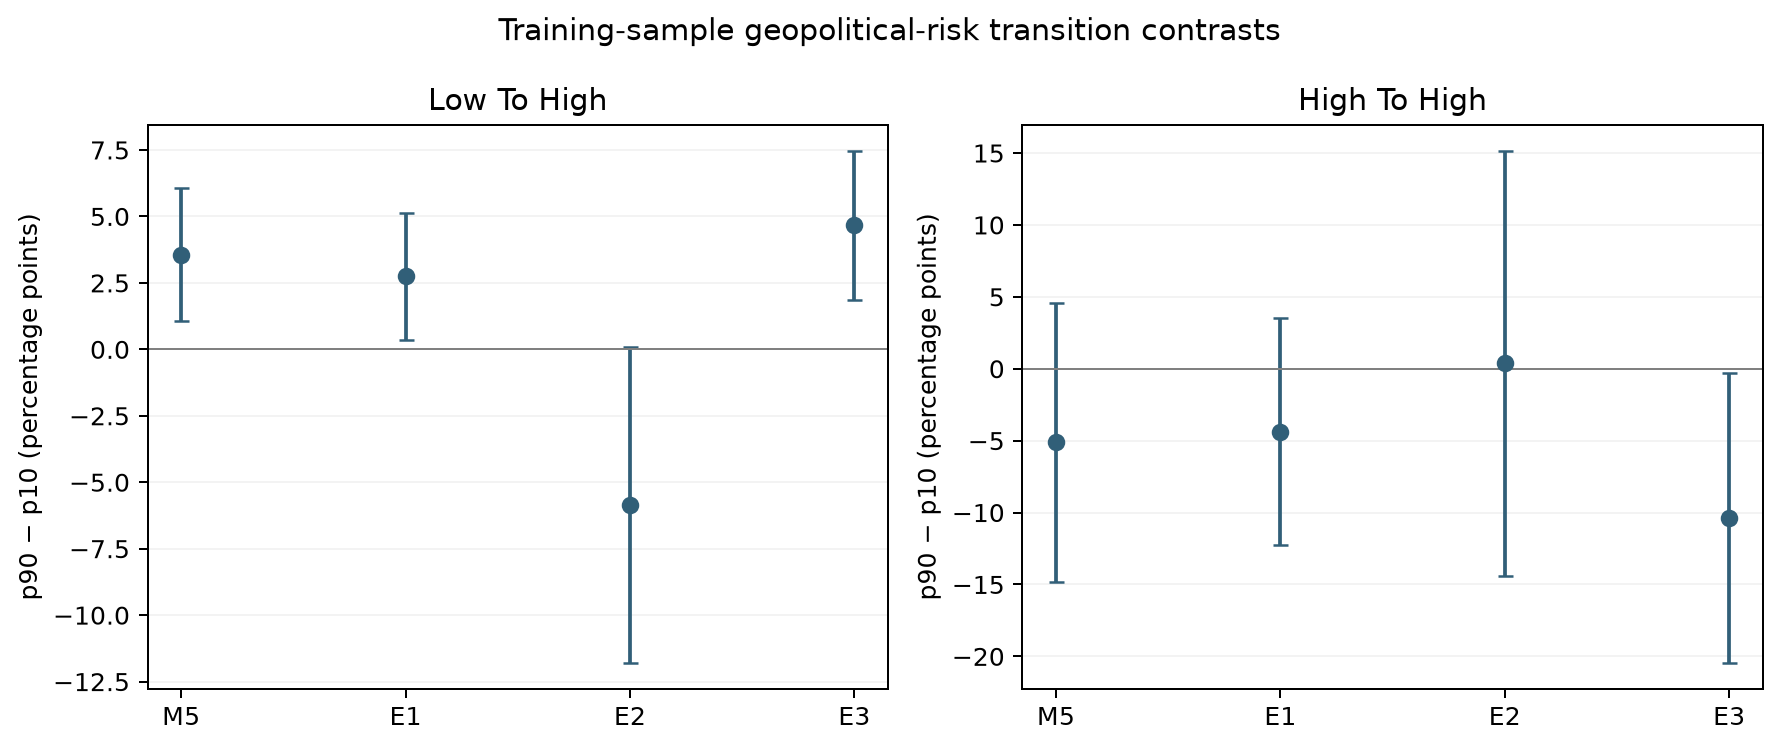

In [4]:
display(Markdown("### Geopolitical-risk percentile scenarios"))
display(results["scenarios"].round(4))
display(Image(filename=str(FIGURES / "07_transition_contrasts.png"), width=900))

In [5]:
display(Markdown("### Validation forecasts — primary extension comparison"))
display(results["score"].query("period == 'validation'").round(5))
display(results["comparisons"].query("period == 'validation'").round(5))
display(Markdown("### 2020–2026 historical evaluation — exploratory"))
display(results["score"].query("period == 'exploratory_test'").round(5))
display(results["comparisons"].query("period == 'exploratory_test'").round(5))

### Validation forecasts — primary extension comparison

,period,model,n,qlike,mse,log_score
5,validation,E1,999,2.43833,89.52397,2.13000
6,validation,E2,999,2.45044,89.88594,2.13314
7,validation,E3,999,2.43632,89.39864,2.12982
8,validation,M4,999,2.44205,89.64238,2.13095
9,validation,M5,999,2.44503,89.72398,2.13230


,period,left,right,n,mean_qlike_left_minus_right,basic_ci95_low,basic_ci95_high,equal_tail_bootstrap_p,block_length,replications,seed
0,validation,M4,E2,999,-0.00839,-0.01995,0.00507,0.18891,10,2000,7207
1,validation,M5,E2,999,-0.00542,-0.01912,0.01127,0.47676,10,2000,7207
2,validation,E1,E2,999,-0.01211,-0.02603,0.00433,0.13693,10,2000,7207
3,validation,E3,E2,999,-0.01413,-0.03029,0.00494,0.14093,10,2000,7207
4,validation,M5,E1,999,0.00669,0.00157,0.01143,0.01000,10,2000,7207


### 2020–2026 historical evaluation — exploratory

,period,model,n,qlike,mse,log_score
0,exploratory_test,E1,1712,3.34419,13411.57931,2.55264
1,exploratory_test,E2,1712,3.42511,13417.41936,2.57069
2,exploratory_test,E3,1712,3.36962,13414.82766,2.55898
3,exploratory_test,M4,1712,3.33639,13411.15209,2.55311
4,exploratory_test,M5,1712,3.33563,13410.00170,2.55035


,period,left,right,n,mean_qlike_left_minus_right,basic_ci95_low,basic_ci95_high,equal_tail_bootstrap_p,block_length,replications,seed
5,exploratory_test,M4,E2,1712,-0.08872,-0.13807,-0.02631,0.01299,10,2000,7207
6,exploratory_test,M5,E2,1712,-0.08948,-0.13838,-0.02933,0.00800,10,2000,7207
7,exploratory_test,E1,E2,1712,-0.08092,-0.12886,-0.02363,0.01199,10,2000,7207
8,exploratory_test,E3,E2,1712,-0.05549,-0.09584,-0.00791,0.02699,10,2000,7207
9,exploratory_test,M5,E1,1712,-0.00855,-0.01658,-0.00017,0.04498,10,2000,7207


In [6]:
display(Markdown("### Convergence and numerical stability across fitting periods"))
display(results["diagnostics"].round(5))
print("Failed attempts:",int((~results["attempts"].valid).sum()),"captured fit warnings:",int(results["attempts"].warning_count.sum()))

### Convergence and numerical stability across fitting periods

,period,model,n,llf,aic,bic,successful_starts,failed_starts,ll_spread,chosen_seed,missing_se,minimum_transition,maximum_transition,minimum_variance,warning_count
0,validation,M4,3699,-8029.99711,16075.99421,16125.72076,3,0,0.00000,41,0,0.00004,0.99996,2.59059,0
1,validation,M5,3699,-8025.59063,16071.18125,16133.33943,3,0,0.00001,103,0,0.00004,0.99996,2.66495,0
2,validation,E1,3699,-8029.25710,16078.51421,16140.67238,3,0,0.00000,103,0,0.00004,0.99996,2.65723,0
3,validation,E2,3699,-8026.97059,16073.94118,16136.09936,3,0,0.00001,67,0,0.00002,0.99998,2.61983,0
4,validation,E3,3699,-8026.73742,16073.47485,16135.63302,3,0,0.00001,41,0,0.00002,0.99998,2.64146,0
5,exploratory_test,M4,4698,-10157.21986,20330.43973,20382.07887,3,0,0.00001,41,0,0.00001,0.99999,2.47885,0
6,exploratory_test,M5,4698,-10153.84265,20327.68530,20392.23422,3,0,0.00016,67,0,0.00001,0.99999,2.53246,0
7,exploratory_test,E1,4698,-10155.46022,20330.92044,20395.46936,3,0,0.00001,103,0,0.00001,0.99999,2.53822,0
8,exploratory_test,E2,4698,-10154.42703,20328.85405,20393.40297,3,0,0.00003,103,0,0.00002,0.99998,2.48186,0
9,exploratory_test,E3,4698,-10152.89414,20325.78828,20390.33720,3,0,0.00001,41,0,0.00000,1.00000,2.52547,0


Failed attempts: 0 captured fit warnings: 0


## Academic interpretation and Stage 07 assessment

**Methodological gate: PASS. Substantive oil-specific forecasting hypothesis: not supported.** All five models use 3,699 identical training returns, 999 validation returns and 1,712 exploratory historical test returns. All 30 independent-start fits converged, with zero captured fit warnings and zero missing standard errors. The fitted transition probabilities are valid but sometimes near deterministic (training minimum about 0.000016 in E2), so boundary-sensitive interpretation remains a limitation.

| Question | Evidence-based answer |
|---|---|
| Stronger oil-specific entry association? | No. E2 Oil GPR p90 minus p10 changes low-to-high probability by **−5.85 percentage points** (delta 95% CI −11.80 to +0.09), whereas M5 original GPR gives **+3.57** (+1.07 to +6.07), E1 general AI-GPR **+2.75** (+0.37 to +5.13), and E3 source-matched keyword GPR **+4.67** (+1.86 to +7.48). Percentile changes are not equal-sized geopolitical shocks across indices. |
| Oil GPR and high-state persistence? | E2 contrast is **+0.38 percentage points** (−14.40 to +15.17); no precise effect is established. |
| Additional information beyond VIX? | E2 improves training AIC over M4 by about 2.05 but worsens BIC by about 10.38. Its validation QLIKE is **2.4504**, versus M4 **2.4420**. In-sample fit does not translate into better validation forecasts. |
| Historical pseudo-out-of-sample forecasting? | Validation M4-minus-E2 QLIKE is **−0.0084**, basic 95% interval −0.0200 to +0.0051; no reliable Oil GPR improvement. On the already-examined 2020–2026 period, E2 QLIKE is **3.4251** versus M4 **3.3364**, an exploratory deterioration. |
| Do newer measures change prior conclusions? | E1 general AI-GPR and E3 source-matched keyword GPR have numerically lower validation QLIKE (2.4383 and 2.4363) than M4 (2.4421), but their exploratory test ranking reverses and multiple specifications have been examined. This does not overturn the Stage 05 conclusion that added GPR has no established reliable, general forecasting gain. |
| Thesis placement? | Treat this as an **appendix or clearly marked retrospective extension**. Retain the original Brent/WTI regime results and Stage 05 forecast findings as the main empirical evidence. |

The AI-GPR source was [published in 2026](https://www.matteoiacoviello.com/ai_gpr.html), and its historical values were reconstructed. The official [methodology paper](https://www.matteoiacoviello.com/research_files/AI_GPR_PAPER.pdf) states that Oil GPR uses LLM classification of geopolitical oil-supply disruption coverage from three newspapers, while `GPR_AER` applies the keyword method to those same sources. The Stages 01–06 GPR series uses broader newspaper coverage. These measures and their percentile shifts are not directly interchangeable. Forecasts using revised historical indices are pseudo-out-of-sample, and the 2020–2026 extension is exploratory because those returns were examined in earlier stages. No causal or verified real-time predictive claim follows.
